In [1]:
print("hi")

hi


In [2]:
from huggingface_hub import snapshot_download
from pathlib import Path

DATASET_REPO = "tlpss/gitw-256x256"

# Download location
DATA_DIR = Path("./data/glasses-in-the-wild")

dataset_path = snapshot_download(
    repo_id=DATASET_REPO,
    repo_type="dataset",
    local_dir=DATA_DIR
)

print(f"Dataset downloaded to: {dataset_path}")

c:\Users\wanlo\Desktop\Beverage_Serving_Robot\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 1005 files: 100%|██████████| 1005/1005 [03:40<00:00,  4.56it/s]

Dataset downloaded to: C:\Users\wanlo\Desktop\Beverage_Serving_Robot\data\glasses-in-the-wild


In [3]:
import json

annotation_path = DATA_DIR / "train" / "annotations.json"

with open(annotation_path, "r") as f:
    annotations = json.load(f)

print("Top-level keys:", annotations.keys())

# Inspect first image entry
print("\nFirst image:")
print(annotations["images"][0])

# Inspect first annotation entry
print("\nFirst annotation:")
print(annotations["annotations"][0])

Top-level keys: dict_keys(['categories', 'images', 'annotations'])

First image:
{'id': 1, 'width': 256, 'height': 256, 'file_name': 'images/anon310_id342_glass0.png'}

First annotation:
{'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [44.79, 59.69, 175.32000000000002, 169.32000000000002], 'keypoints': [99.1, 214.9, 2.0, 59.4, 73.8, 2.0, 205.5, 108.1, 2.0, 118.4, 141.0, 2.0, 110.9, 169.6, 2.0], 'num_keypoints': 5}


In [4]:
import pandas as pd
from PIL import Image

KEYPOINT_NAMES = [
    "bottom_front",
    "top_left",
    "top_right",
    "top_front",
    "fluid_level"
]

all_rows = []

for split in ["train", "val", "test"]:

    annotation_path = DATA_DIR / split / "annotations.json"
    image_dir = DATA_DIR / split

    with open(annotation_path, "r") as f:
        data = json.load(f)

    # Map image IDs to image metadata
    image_lookup = {
        image["id"]: image
        for image in data["images"]
    }

    # Match annotations to images using image_id
    for annotation in data["annotations"]:

        image_info = image_lookup[annotation["image_id"]]

        filename = image_info["file_name"]
        image_path = image_dir / filename

        keypoints = annotation["keypoints"]

        row = {
            "split": split,
            "image_id": annotation["image_id"],
            "filename": filename,
            "image_path": str(image_path),
            "width": image_info["width"],
            "height": image_info["height"],
        }

        # Extract individual keypoint coordinates
        for i, name in enumerate(KEYPOINT_NAMES):

            x = keypoints[i * 3]
            y = keypoints[i * 3 + 1]
            visibility = keypoints[i * 3 + 2]

            row[f"{name}_x"] = x
            row[f"{name}_y"] = y
            row[f"{name}_visibility"] = visibility

        all_rows.append(row)


# Create DataFrame
df = pd.DataFrame(all_rows)

print(f"Total images: {len(df)}")
print(f"Columns: {len(df.columns)}")

df.head()

Total images: 1000
Columns: 21


,split,image_id,filename,image_path,width,height,bottom_front_x,bottom_front_y,bottom_front_visibility,top_left_x,...,top_left_visibility,top_right_x,top_right_y,top_right_visibility,top_front_x,top_front_y,top_front_visibility,fluid_level_x,fluid_level_y,fluid_level_visibility
0,train,1,images/anon310_id342_glass0.png,data\glasses-in-the-wild\train\images\anon310_...,256,256,99.1,214.9,2.0,59.4,...,2.0,205.5,108.1,2.0,118.4,141.0,2.0,110.9,169.6,2.0
1,train,2,images/anon311_id365_glass0.png,data\glasses-in-the-wild\train\images\anon311_...,256,256,112.8,216.3,2.0,63.0,...,2.0,203.1,79.3,2.0,127.0,110.0,2.0,116.5,178.9,2.0
2,train,3,images/anon311_id366_glass1.png,data\glasses-in-the-wild\train\images\anon311_...,256,256,97.0,216.0,2.0,84.1,...,2.0,208.0,101.0,2.0,129.0,120.9,2.0,106.9,184.7,2.0
3,train,4,images/anon311_id367_glass2.png,data\glasses-in-the-wild\train\images\anon311_...,256,256,127.4,216.6,2.0,60.4,...,2.0,207.7,93.6,2.0,130.7,132.2,2.0,127.6,222.1,2.0
4,train,5,images/anon311_id368_glass3.png,data\glasses-in-the-wild\train\images\anon311_...,256,256,126.0,193.5,2.0,51.6,...,2.0,203.6,95.2,2.0,127.6,146.7,2.0,125.9,189.1,2.0


In [5]:
df["image_exists"] = df["image_path"].apply(
    lambda path: Path(path).exists()
)

print("Total records:", len(df))
print("Images found:", df["image_exists"].sum())
print("Missing images:", (~df["image_exists"]).sum())

print("\nRecords by split:")
print(df["split"].value_counts())

Total records: 1000
Images found: 1000
Missing images: 0

Records by split:
split
train    621
test     310
val       69
Name: count, dtype: int64


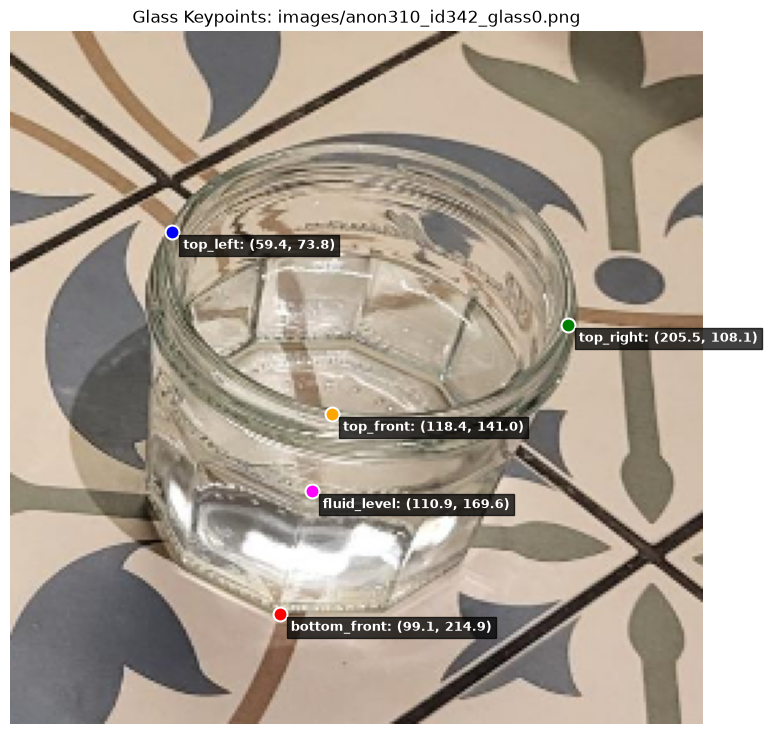

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

sample = df.iloc[0]
image = Image.open(sample["image_path"])

plt.figure(figsize=(9, 9))
plt.imshow(image)

keypoint_colors = {
    "bottom_front": "red",
    "top_left": "blue",
    "top_right": "green",
    "top_front": "orange",
    "fluid_level": "magenta"
}

for name in KEYPOINT_NAMES:
    x = sample[f"{name}_x"]
    y = sample[f"{name}_y"]

    plt.scatter(
        x, y,
        s=100,
        color=keypoint_colors[name],
        edgecolors="white",
        linewidths=1.5
    )

    plt.annotate(
        f"{name}: ({x:.1f}, {y:.1f})",
        (x, y),
        xytext=(8, -12),
        textcoords="offset points",
        color="white",
        fontsize=9,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.75, pad=3)
    )

plt.title(f"Glass Keypoints: {sample['filename']}")
plt.axis("off")
plt.show()